# Stemming and Lemitization


## Stemming

In [1]:
from nltk.stem import PorterStemmer #stemming import command
stemmer = PorterStemmer()
words = ["running", "studying", "smiling", "communication"]
stemmed_words = [stemmer.stem(word) for word in words]
print(stemmed_words)

['run', 'studi', 'smile', 'commun']


## Lemitization


In [2]:
import nltk
from nltk.stem import WordNetLemmatizer
from nltk.corpus import wordnet
nltk.download('wordnet')
lemmatizer = WordNetLemmatizer()
words = ["running", "better", "studies", "was"]
lemmas = [
    lemmatizer.lemmatize("running", pos=wordnet.VERB),
    lemmatizer.lemmatize("better", pos=wordnet.ADJ),
    lemmatizer.lemmatize("studies", pos=wordnet.NOUN),
    lemmatizer.lemmatize("was", pos=wordnet.VERB)
]
print(lemmas)

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


['run', 'good', 'study', 'be']


### Data load

In [3]:
import pandas as pd

In [4]:
data = pd.read_csv("/content/twitter_training.csv", header=None)
data

,0,1,2,3
0,2401,Borderlands,Positive,im getting on borderlands and i will murder yo...
1,2401,Borderlands,Positive,I am coming to the borders and I will kill you...
2,2401,Borderlands,Positive,im getting on borderlands and i will kill you ...
3,2401,Borderlands,Positive,im coming on borderlands and i will murder you...
4,2401,Borderlands,Positive,im getting on borderlands 2 and i will murder ...
...,...,...,...,...
23999,4513,Google,Neutral,"A truly incredible game. Gaming is the ""show o..."
24000,4514,Google,Neutral,“Android Becomes Basically Unusable If You Tur...
24001,4514,Google,Neutral,"""Android basically becomes useless if you turn..."
24002,4514,Google,Neutral,"""Android Becomes the Unusable If You Turn Off ..."


In [5]:
data.drop([0,1],axis=1,inplace=True)

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24004 entries, 0 to 24003
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   2       24004 non-null  object
 1   3       23784 non-null  object
dtypes: object(2)
memory usage: 375.2+ KB


In [7]:
data.isna().sum()

,0
2,0
3,220


In [8]:
data.dropna(inplace=True)

In [9]:
data.isna().sum()

,0
2,0
3,0


In [10]:
data.rename(columns={2:"Sentiment",3:"Review"},inplace=True)

In [11]:
data

,Sentiment,Review
0,Positive,im getting on borderlands and i will murder yo...
1,Positive,I am coming to the borders and I will kill you...
2,Positive,im getting on borderlands and i will kill you ...
3,Positive,im coming on borderlands and i will murder you...
4,Positive,im getting on borderlands 2 and i will murder ...
...,...,...
23999,Neutral,"A truly incredible game. Gaming is the ""show o..."
24000,Neutral,“Android Becomes Basically Unusable If You Tur...
24001,Neutral,"""Android basically becomes useless if you turn..."
24002,Neutral,"""Android Becomes the Unusable If You Turn Off ..."


In [12]:
data.duplicated().sum()

np.int64(1297)

In [13]:
data.drop_duplicates(inplace=True)

In [14]:
data.duplicated().sum()

np.int64(0)

<Axes: xlabel='Sentiment'>

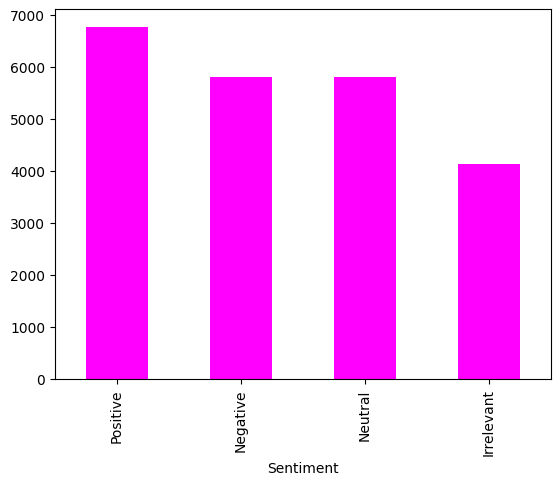

In [15]:
data.Sentiment.value_counts().plot(kind="bar", color = 'magenta')

In [16]:
data

,Sentiment,Review
0,Positive,im getting on borderlands and i will murder yo...
1,Positive,I am coming to the borders and I will kill you...
2,Positive,im getting on borderlands and i will kill you ...
3,Positive,im coming on borderlands and i will murder you...
4,Positive,im getting on borderlands 2 and i will murder ...
...,...,...
23999,Neutral,"A truly incredible game. Gaming is the ""show o..."
24000,Neutral,“Android Becomes Basically Unusable If You Tur...
24001,Neutral,"""Android basically becomes useless if you turn..."
24002,Neutral,"""Android Becomes the Unusable If You Turn Off ..."


In [17]:
import string
import nltk
import re
from nltk.corpus import stopwords
nltk.download('stopwords')
def Text_Preprocessor(text):
  text = text.lower()
  text = re.sub("\d","",text)
  text = re.sub("\s+"," ",text)
  text = text.encode("ascii","ignore").decode("ascii")
  text = text.replace(string.punctuation,'')
  text = " ".join([a for a in text.split() if a not in stopwords.words('english')])
  return text

<>:8: SyntaxWarning: invalid escape sequence '\d'
<>:9: SyntaxWarning: invalid escape sequence '\s'
<>:8: SyntaxWarning: invalid escape sequence '\d'
<>:9: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_1383/3877630433.py:8: SyntaxWarning: invalid escape sequence '\d'
  text = re.sub("\d","",text)
/tmp/ipykernel_1383/3877630433.py:9: SyntaxWarning: invalid escape sequence '\s'
  text = re.sub("\s+"," ",text)
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [18]:
data['Review'] = data['Review'].apply(Text_Preprocessor)

In [19]:
print(data.Review[0])

im getting borderlands murder ,
